In [208]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [209]:
GROUP = "C5"
DTYPE="GLCM"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C5_10,28,"[DATA/TRAINING/C5/C5_10/IMG_7706.HEIC, DATA/TR..."
1,C5_11,30,"[DATA/TRAINING/C5/C5_11/IMG_7780.HEIC, DATA/TR..."
2,C5_12,26,"[DATA/TRAINING/C5/C5_12/IMG_7858.HEIC, DATA/TR..."
3,C5_13,27,"[DATA/TRAINING/C5/C5_13/IMG_7917.HEIC, DATA/TR..."
4,C5_14,27,"[DATA/TRAINING/C5/C5_14/IMG_7981.HEIC, DATA/TR..."
5,C5_15,28,"[DATA/TRAINING/C5/C5_15/IMG_8046.jpg, DATA/TRA..."
6,C5_16,25,"[DATA/TRAINING/C5/C5_16/IMG_8109.HEIC, DATA/TR..."


In [210]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [211]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [212]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [213]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

Text(0.5, 1.0, '16% IMG_8140.HEIC')

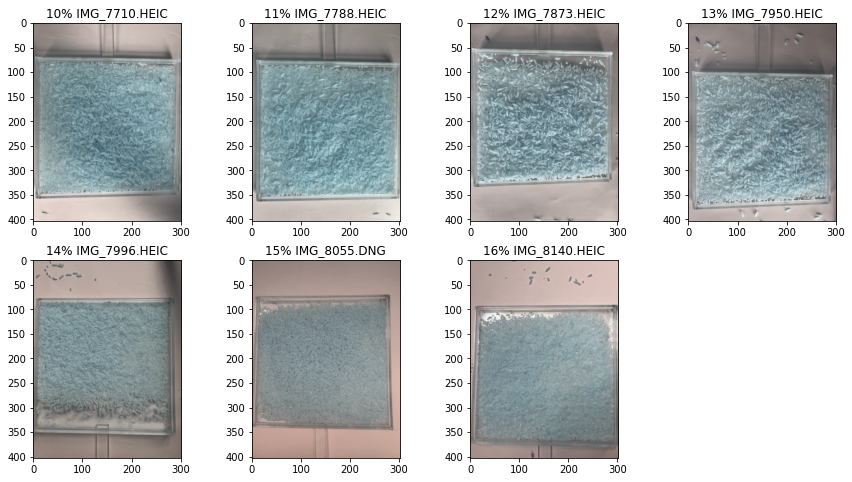

In [214]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [228]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [229]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,115.745880,256.784628,216.413819,268.247852,7.314794,10.967614,9.573669,11.375224,0.203713,0.148988,...,0.000542,0.000395,0.000436,0.000375,3,120,90,3,IMG_7706.HEIC,10
1,102.447472,227.882447,186.759290,231.699462,6.864139,10.171372,8.729225,10.423662,0.214388,0.153858,...,0.000578,0.000417,0.000473,0.000401,3,120,90,3,IMG_7709.HEIC,10
2,111.479401,231.535171,191.679272,243.274195,7.243258,10.600415,9.131746,10.959399,0.203256,0.143278,...,0.000529,0.000392,0.000451,0.000373,3,120,90,3,IMG_7710.HEIC,10
3,144.178464,308.818714,234.193931,283.166651,8.038577,12.361156,10.050700,11.637617,0.225327,0.136046,...,0.000584,0.000412,0.000508,0.000438,3,120,90,3,IMG_7713.HEIC,10
4,134.869101,326.793032,259.484500,297.486168,7.891011,12.488245,10.428852,11.816259,0.226246,0.136898,...,0.000598,0.000428,0.000514,0.000437,3,120,90,3,IMG_7714.HEIC,10
5,124.037547,265.340195,205.282540,247.168539,7.521442,11.406855,9.436415,10.955717,0.228648,0.143696,...,0.000668,0.000508,0.000618,0.000510,3,120,90,3,IMG_7718.HEIC,10
6,168.200187,333.956661,245.758357,296.539326,8.647191,12.924842,10.568627,12.160514,0.218453,0.129351,...,0.000528,0.000392,0.000471,0.000405,3,120,90,3,IMG_7719.HEIC,10
7,140.779307,284.673402,221.223063,261.713247,8.132678,12.061373,10.054809,11.478897,0.227906,0.136333,...,0.000690,0.000503,0.000601,0.000523,3,120,90,3,IMG_7721.HEIC,10
8,119.435581,266.317062,201.489823,239.966764,7.414794,11.394958,9.228385,10.663016,0.242271,0.141780,...,0.000774,0.000549,0.000708,0.000578,3,120,90,3,IMG_7723.HEIC,10
9,104.878745,245.149750,191.711671,224.115287,6.827247,10.759985,8.902708,10.221981,0.253728,0.150532,...,0.000929,0.000646,0.000829,0.000658,3,120,90,3,IMG_7725.HEIC,10


# Classification

In [181]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [182]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [183]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [184]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [185]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [186]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.900000,0.916667,0.904762,0.910675,GLCM,C5,RF_C,25,1008,756,3
1,2,0.894737,0.904762,0.904762,0.904762,GLCM,C5,RF_C,25,1008,756,3
2,3,0.789474,0.859524,0.809524,0.833775,GLCM,C5,RF_C,25,1008,756,3
3,4,0.789474,0.750000,0.761905,0.755906,GLCM,C5,RF_C,25,1008,756,3
4,5,0.736842,0.761905,0.738095,0.749811,GLCM,C5,RF_C,25,1008,756,3
5,6,0.842105,0.871429,0.857143,0.864227,GLCM,C5,RF_C,25,1008,756,3
6,7,0.789474,0.845238,0.761905,0.801411,GLCM,C5,RF_C,25,1008,756,3
7,8,0.894737,0.928571,0.904762,0.916512,GLCM,C5,RF_C,25,1008,756,3
8,9,0.842105,0.773810,0.809524,0.791264,GLCM,C5,RF_C,25,1008,756,3
9,10,1.000000,1.000000,1.000000,1.000000,GLCM,C5,RF_C,25,1008,756,3


In [187]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C5,RF_C,0.847895,0.845238,0.852834,0.86119


### MLP Classifier

In [188]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [189]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [190]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.900000,0.916667,0.904762,0.910675,GLCM,C5,MLP_C,25,1008,756,3
1,2,1.000000,1.000000,1.000000,1.000000,GLCM,C5,MLP_C,25,1008,756,3
2,3,0.894737,0.928571,0.904762,0.916512,GLCM,C5,MLP_C,25,1008,756,3
3,4,0.894737,0.928571,0.880952,0.904135,GLCM,C5,MLP_C,25,1008,756,3
4,5,0.578947,0.621429,0.595238,0.608051,GLCM,C5,MLP_C,25,1008,756,3
5,6,0.789474,0.833333,0.785714,0.808824,GLCM,C5,MLP_C,25,1008,756,3
6,7,0.842105,0.880952,0.833333,0.856481,GLCM,C5,MLP_C,25,1008,756,3
7,8,0.631579,0.676190,0.666667,0.671395,GLCM,C5,MLP_C,25,1008,756,3
8,9,0.578947,0.580952,0.571429,0.576151,GLCM,C5,MLP_C,25,1008,756,3
9,10,0.894737,0.928571,0.904762,0.916512,GLCM,C5,MLP_C,25,1008,756,3


In [191]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C5,MLP_C,0.800526,0.804762,0.816874,0.829524


### XGBoost Classifier

In [192]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [193]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.700000,0.750000,0.714286,0.731707,GLCM,C5,XGB_C,25,1008,756,3
1,2,0.684211,0.728571,0.642857,0.683036,GLCM,C5,XGB_C,25,1008,756,3
2,3,1.000000,1.000000,1.000000,1.000000,GLCM,C5,XGB_C,25,1008,756,3
3,4,0.947368,0.964286,0.952381,0.958296,GLCM,C5,XGB_C,25,1008,756,3
4,5,0.842105,0.880952,0.857143,0.868885,GLCM,C5,XGB_C,25,1008,756,3
5,6,0.894737,0.928571,0.904762,0.916512,GLCM,C5,XGB_C,25,1008,756,3
6,7,0.736842,0.776190,0.738095,0.756664,GLCM,C5,XGB_C,25,1008,756,3
7,8,0.736842,0.788095,0.761905,0.774779,GLCM,C5,XGB_C,25,1008,756,3
8,9,0.894737,0.928571,0.857143,0.891429,GLCM,C5,XGB_C,25,1008,756,3
9,10,0.631579,0.711905,0.619048,0.662237,GLCM,C5,XGB_C,25,1008,756,3


In [194]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C5,XGB_C,0.806842,0.804762,0.824354,0.845714


# External validation

In [195]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C5_10,5,"[DATA/TEST/C5/C5_10/IMG_7696.HEIC, DATA/TEST/C..."
1,C5_11,5,"[DATA/TEST/C5/C5_11/IMG_7770.HEIC, DATA/TEST/C..."
2,C5_12,5,"[DATA/TEST/C5/C5_12/IMG_7847.HEIC, DATA/TEST/C..."
3,C5_13,5,"[DATA/TEST/C5/C5_13/IMG_7908.HEIC, DATA/TEST/C..."
4,C5_14,5,"[DATA/TEST/C5/C5_14/IMG_7971.HEIC, DATA/TEST/C..."
5,C5_15,5,"[DATA/TEST/C5/C5_15/IMG_8037.DNG, DATA/TEST/C5..."
6,C5_16,5,"[DATA/TEST/C5/C5_16/IMG._8128.HEIC, DATA/TEST/..."


In [196]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [197]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])

        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [198]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,65.065003,132.054685,94.669668,128.794210,4.394744,6.513686,5.380315,6.476182,0.306170,0.232709,...,0.000676,0.000471,0.000571,0.000467,25,1008,756,3,IMG_7696.HEIC,10
1,57.684957,115.172905,80.958645,112.522687,4.160055,6.013974,4.929006,6.039405,0.316120,0.246414,...,0.000755,0.000550,0.000664,0.000532,25,1008,756,3,IMG_7698.HEIC,10
2,63.788610,127.402398,89.519156,125.339254,4.366861,6.390417,5.195340,6.377120,0.307504,0.235368,...,0.000659,0.000468,0.000579,0.000461,25,1008,756,3,IMG_7701.HEIC,10
3,59.858946,115.769390,83.034096,119.952662,4.197372,6.066403,4.999975,6.211266,0.317199,0.245279,...,0.000687,0.000489,0.000597,0.000471,25,1008,756,3,IMG_7702.HEIC,10
4,64.226085,121.412424,85.114461,124.348134,4.306454,6.135464,4.984250,6.249363,0.315353,0.245686,...,0.000683,0.000493,0.000607,0.000477,25,1008,756,3,IMG_7704.HEIC,10
0,68.706249,137.018283,86.483035,119.805693,4.445385,6.595394,5.092822,6.223320,0.319613,0.236363,...,0.000660,0.000443,0.000570,0.000456,25,1008,756,3,IMG_7770.HEIC,11
1,66.963453,135.228383,83.829533,113.586434,4.418840,6.579550,5.032738,6.070981,0.314609,0.234712,...,0.000685,0.000466,0.000604,0.000485,25,1008,756,3,IMG_7771.HEIC,11
2,60.769815,127.184668,83.485652,115.072565,4.183591,6.269014,4.912358,6.040049,0.329593,0.247390,...,0.000761,0.000522,0.000673,0.000525,25,1008,756,3,IMG_7775.HEIC,11
3,64.304127,130.427008,83.384471,113.543396,4.411162,6.522057,5.053802,6.165450,0.310041,0.231013,...,0.000720,0.000493,0.000635,0.000503,25,1008,756,3,IMG_7776.HEIC,11
4,65.828935,136.870470,86.783665,115.650835,4.398743,6.598045,5.057886,6.100885,0.316383,0.231850,...,0.000699,0.000461,0.000596,0.000483,25,1008,756,3,IMG_7779.HEIC,11


In [199]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [200]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [201]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [202]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [203]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.80      0.80      0.80         5
     Class 1       0.80      0.80      0.80         5
     Class 2       0.50      0.80      0.62         5
     Class 3       0.50      0.20      0.29         5
     Class 4       1.00      0.80      0.89         5
     Class 5       0.71      1.00      0.83         5
     Class 6       0.75      0.60      0.67         5

    accuracy                           0.71        35
   macro avg       0.72      0.71      0.70        35
weighted avg       0.72      0.71      0.70        35



## MLP

In [204]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [205]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.20      0.33         5
     Class 1       0.56      1.00      0.71         5
     Class 2       0.56      1.00      0.71         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.71        35
   macro avg       0.68      0.71      0.64        35
weighted avg       0.68      0.71      0.64        35



## XGBC

In [206]:
y_pred = modelXGBC.predict(X_test_scale) 

In [207]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       0.71      1.00      0.83         5
     Class 2       0.83      1.00      0.91         5
     Class 3       1.00      0.60      0.75         5
     Class 4       0.75      0.60      0.67         5
     Class 5       0.83      1.00      0.91         5
     Class 6       0.67      0.80      0.73         5

    accuracy                           0.80        35
   macro avg       0.83      0.80      0.79        35
weighted avg       0.83      0.80      0.79        35

